# TopoPyScale in the Pyrenees (1/2): downscaling ERA5 along a North–South transect

**Workshop demo.** We downscale ERA5 (2019–2020) with [TopoPyScale](https://github.com/ArcticSnow/TopoPyScale)
along a 30 km wide transect across the whole Pyrenees, from the Ebro basin (Huesca) to the Béarn piedmont (Pau).
This notebook runs TopoPyScale step by step and needs no previous experience with it.
[`2_analysis.ipynb`](2_analysis.ipynb) then analyses the results.

**Why downscale?** ERA5 gives one value per ~31 km grid cell, on a smoothed terrain that reaches only ~1400 m here,
while the real valleys and summits range from ~400 m to ~3000 m. Temperature, pressure, humidity, radiation and snow
all depend on that terrain.

**What TopoPyScale does.** It combines ERA5 with a high-resolution digital elevation model (DEM, here 30 m):

* **3-D interpolation**: horizontal inverse-distance weighting between ERA5 cells + vertical interpolation in the
  *pressure-level* profiles (T, humidity, wind) to the real elevation of each point; pressure is recomputed
  hypsometrically.
* **Terrain-aware radiation**: shortwave split into direct/diffuse, then corrected for slope/aspect
  (illumination angle), cast shadows (horizon angles) and sky-view factor; longwave corrected for sky-view and
  terrain emission.
* **TopoSUB**: instead of computing every DEM pixel, pixels are clustered by (x, y, elevation, slope, aspect,
  sky-view) and only the cluster centroids are downscaled; results are mapped back to the grid.

**How TopoPyScale is run.** Each run is a *project*: a folder with a configuration file `config.yml`, an `inputs/`
folder (DEM and ERA5) and an `outputs/` folder. In Python, `mp = Topoclass("config.yml")` reads the configuration;
then one method per step does the work and writes its result to `outputs/`. The sections below follow these steps,
with the same numbers and names as in the workflow figure. A step whose output file already exists is not
recomputed, so a second run of this notebook takes a few minutes.

This notebook runs three projects:

| project | what is downscaled | mode |
|---|---|---|
| `transect_light` | the transect, as 300 clusters | light and full |
| `transect_full` | the transect, as 3000 clusters | full |
| `izas` | 17 points around the Izas weather station (for the validation) | light and full |

Notebook 2 analyses `transect_light` in light mode and `transect_full` in full mode. With hourly ERA5
(`ERA5_TIMESTEP = "1h"`) the projects get a `_1h` suffix (`transect_light_1h`, `transect_full_1h`, `izas_1h`).

> **Data note.** The ERA5 files provided for the workshop are **6-hourly** (00, 06, 12, 18 UTC). Radiation and
> precipitation are the 1-hour accumulations ending at those times. We downscale at this native 6-hourly step,
> so SW values are *1-hour means at 4 times of the day*, not daily means.

> **Hourly ERA5.** With `ERA5_TIMESTEP = "1h"` the notebook downscales hourly ERA5 instead, for 1 November 2019 –
> 30 April 2020 (downloaded with `download_era5_1h.py`). Radiation and precipitation are then 1-hour values at every
> hour.

## Setup

Three switches:

* `MODE`: `"light"` runs the transect with 300 clusters (fine on a laptop); `"full"` also runs it with 3000
  clusters, which notebook 2 then analyses.
* `ERA5_TIMESTEP`: `"6h"` downscales the ERA5 provided for the workshop (6-hourly, 2019–2020); `"1h"` downscales
  hourly ERA5 for 1 November 2019 – 30 April 2020, in separate projects ending in `_1h`. Terrain, clusters and
  horizons do not depend on the time step: the hourly projects re-use those of the 6-hourly ones.
* `CPU_CORES`: at most 20, since this is a shared machine.

The data folder comes from `data_links.yml` (see the README).

In [1]:
import os

######################################################################################################################
# Switches
MODE = "full"                           # "light": 300 clusters (laptops); "full": 300 and 3000 clusters
ERA5_TIMESTEP = "6h"                   # "6h": provided ERA5, 2019-2020; "1h": hourly ERA5, Nov 2019 - Apr 2020
CPU_CORES = min(20, os.cpu_count())    # shared machine: at most 20 cores

######################################################################################################################
# Imports. TopoPyScale runs CPU_CORES worker processes: one thread each keeps the total at CPU_CORES cores
for v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "DASK_NUM_WORKERS"):
    os.environ[v] = "1"
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib.patches import Rectangle
import dask
from threadpoolctl import threadpool_limits

from TopoPyScale import topoclass as tc
import pyr_utils as pu

dask.config.set(num_workers=CPU_CORES)  # the notebook process itself (e.g. reading, clustering) may use CPU_CORES
_limits = threadpool_limits(CPU_CORES)  # threads

######################################################################################################################
# Paths and helpers
RUNS = {"light": [300], "full": [300, 3000]}[MODE]          # number of clusters of each transect run
N = max(RUNS)                                               # the run analysed in notebook 2
DEM_RES = 30.0                                             # m
START, END = {"6h": ("2019-01-01", "2020-12-31"), "1h": ("2019-11-01", "2020-04-30")}[ERA5_TIMESTEP]  # period
SUFFIX = "" if ERA5_TIMESTEP == "6h" else f"_{ERA5_TIMESTEP}"   # project folders of the hourly run end in _1h
TAG = "" if ERA5_TIMESTEP == "6h" else f" ({ERA5_TIMESTEP})"    # in the compute-time labels of steps 3 and 5

CODE_DIR = Path.cwd()
LINKS = pu.load_links()                                    # private workshop links: data_links.yml (not in git)
DATA_ROOT = Path(os.environ.get("TPS_PYR_DATA") or LINKS.get("data_root") or CODE_DIR / "data")
CLIM_6H = DATA_ROOT / "era5_topopyscale"                   # 6-hourly ERA5 re-formatted for TopoPyScale
CLIM = CLIM_6H if ERA5_TIMESTEP == "6h" else DATA_ROOT / "era5_1h" / "topopyscale"   # the ERA5 downscaled here
PROJ = {300: DATA_ROOT / f"transect_light{SUFFIX}", 3000: DATA_ROOT / f"transect_full{SUFFIX}"}   # transect projects
PROJ_I = DATA_ROOT / f"izas{SUFFIX}"                       # points project (Izas)
PROJ_6H = {300: DATA_ROOT / "transect_light", 3000: DATA_ROOT / "transect_full"}  # 6-hourly projects, re-used by 1h
PROJ_I_6H = DATA_ROOT / "izas"
TIMES_FILE = DATA_ROOT / "compute_times.json"              # compute time of each step, kept across runs


def timed(label, cached=False):
    """Time a step. When it is only loaded from disk, report the time it took when it was actually computed."""
    return pu.timed(label, TIMES_FILE, cached)


km = pu.km
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
print(f"MODE={MODE}: transect runs with {RUNS} clusters; ERA5 {ERA5_TIMESTEP}, {START} to {END}; CPU_CORES={CPU_CORES}")

MODE=full: transect runs with [300, 3000] clusters; ERA5 6h, 2019-01-01 to 2020-12-31; CPU_CORES=20


## The workflow

The five TopoPyScale steps, numbered as in the sections below; the boxes on the left are the inputs. Each box gives
the `Topoclass` method that runs the step and the file it writes in `outputs/`. Steps 1 and 4 work on every pixel of
the DEM: they are the slow ones, but they do not depend on the number of clusters and are computed only once.
The times are those of the runs already done.

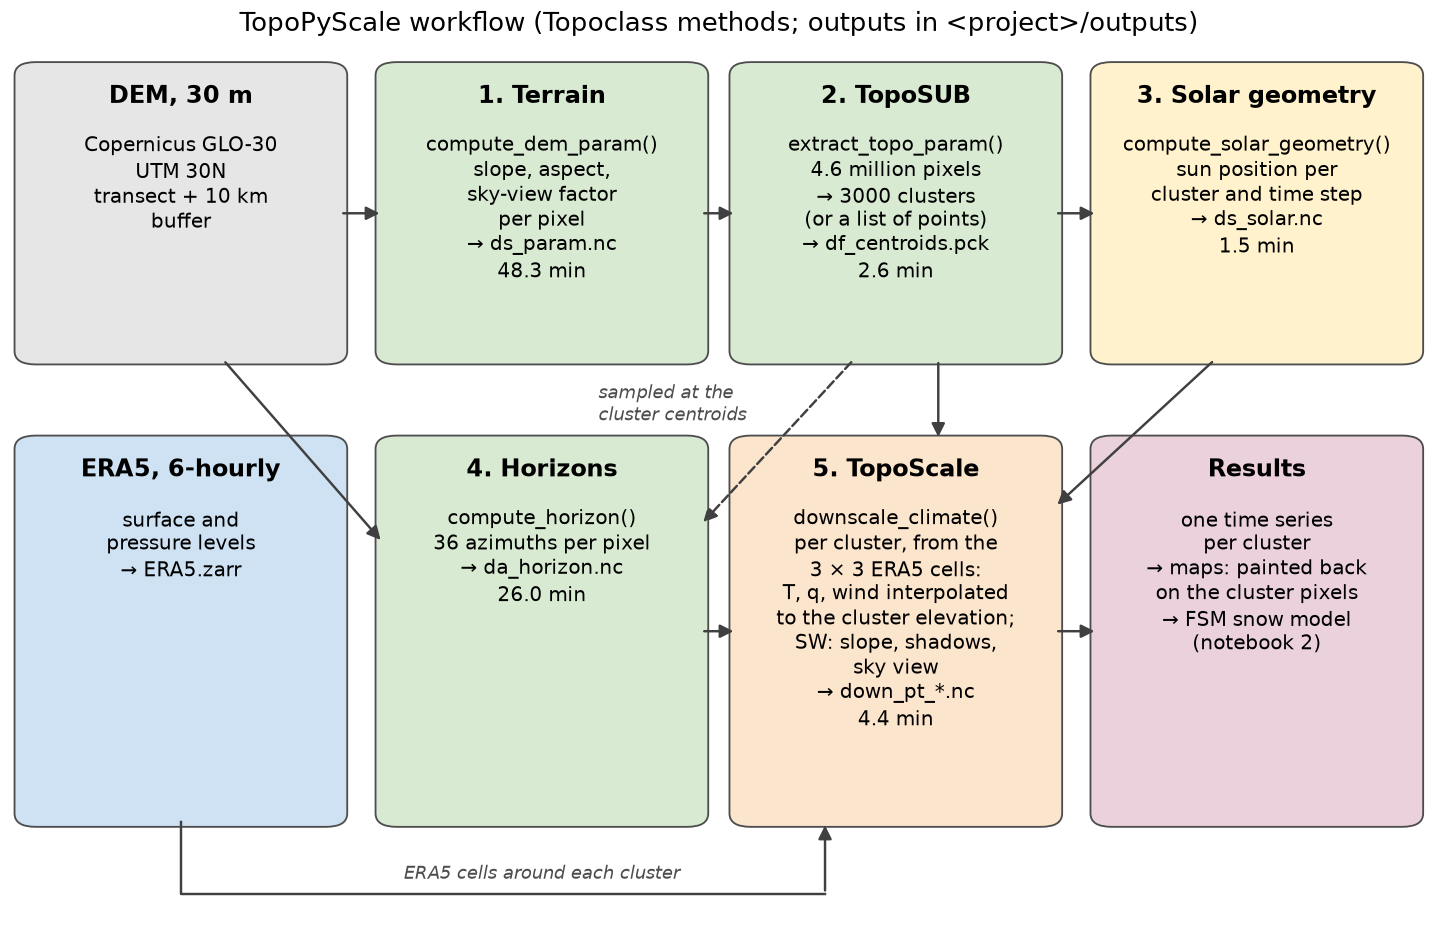

In [2]:
######################################################################################################################
# Figure: workflow
pu.plot_workflow(pu.load_times(TIMES_FILE), N, ERA5_TIMESTEP, TAG)
plt.show()

## Inputs: DEM and ERA5

* **DEM, 30 m**: two Copernicus GLO-30 tiles, reprojected to UTM 30N over the transect plus a 10 km buffer, so that
  horizons and sky view near the edges see the surrounding mountains. A mask marks the transect itself: only the
  transect is clustered and downscaled.
* **ERA5, 6-hourly**: surface fields (2 m temperature and dew point, pressure, radiation, precipitation) and
  pressure-level fields (temperature, humidity, wind and geopotential from 1000 to 600 hPa). The daily files provided
  for the workshop are merged into the yearly `SURF_YYYY.nc` / `PLEV_YYYY.nc` files TopoPyScale reads, checked, and
  converted to a zarr store (`ERA5.zarr`), which makes step 5 more than 10 times faster.
  With `ERA5_TIMESTEP = "1h"`, the hourly files downloaded with `download_era5_1h.py` (in `<data>/era5_1h/monthly`)
  are prepared the same way and checked against the 6-hourly ones at 00, 06, 12 and 18 UTC.

`T_EX`, the time step shown in the maps below, is the clearest December/January noon of the ERA5 period.

Maps of the transect and of the ERA5 grid are in notebook 2.

In [3]:
######################################################################################################################
# Processing: inputs
with timed("Inputs: download + ERA5 preparation", cached=(CLIM_6H / "ERA5.zarr").exists()):
    paths = pu.download_inputs(DATA_ROOT / "raw", LINKS)
    era5_info = pu.prepare_era5(paths["era5_daily"], CLIM_6H)   # daily files -> yearly SURF_/PLEV_ + checks
    print("zarr store:", pu.build_zarr(CLIM_6H).name)          # yearly files -> ERA5.zarr (fast downscaling)
if ERA5_TIMESTEP == "1h":                                    # hourly ERA5 (download_era5_1h.py), same grid
    with timed("Inputs: hourly ERA5 preparation", cached=(CLIM / "ERA5.zarr").exists()):
        if not (CLIM / "ERA5.zarr").exists():
            pu.prepare_era5_1h(DATA_ROOT / "era5_1h" / "monthly", CLIM, ref_dir=CLIM_6H, start=START, end=END)
        print("zarr store:", pu.build_zarr(CLIM).name)
T_EX = pu.clearest_winter_noon(CLIM)                         # example time step of the maps: a clear winter noon
print("T_EX:", T_EX)

tb, db = pu.transect_bounds(res=DEM_RES, buffer_km=10)       # UTM bounds of the transect and of the buffered DEM
DEM_FILE = DATA_ROOT / "dem" / "dem_transect_30m.tif"
MASK_FILE = DATA_ROOT / "dem" / "transect_mask.tif"          # 1 = transect (clustered), 0 = buffer
with timed("Inputs: DEM", cached=DEM_FILE.exists()):
    dem = pu.build_dem(paths["dem_tiles"], DEM_FILE, db, res=DEM_RES, mask_tif=MASK_FILE, mask_bounds=tb)

x_izas, y_izas = pu.to_utm.transform(pu.IZAS["lon"], pu.IZAS["lat"])
zoom = (tb[0], y_izas - 18e3, tb[2], y_izas + 18e3)          # maps below: 36 km around Izas, full transect width

  found ERA5_Pyr_2019_2020.zip
  found Izas_Meteo_2019-2021.xlsx
  found Copernicus_DSM_COG_10_N42_00_W001_00_DEM.tif
  found Copernicus_DSM_COG_10_N43_00_W001_00_DEM.tif
  found SURF_2019.nc, PLEV_2019.nc
  found SURF_2020.nc, PLEV_2020.nc


  ERA5 checks passed: {'n_times': 2924, 'lat': (41.62, 43.87), 'lon': (-1.560733333333332, 0.689566666666668), 'levels': [600.0, 650.0, 700.0, 750.0, 800.0, 850.0, 900.0, 950.0, 1000.0], 'ssrd_max_Wm2': 1002.9161111111111, 'tp_max_mm_per_h': 12.331008911132812}
zarr store: ERA5.zarr
[Inputs: download + ERA5 preparation] loaded from disk in 1 s (computed in 4.0 min)


T_EX: 2019-01-24 12:00:00


  dem_transect_30m.tif: 5294 x 1667 px (8.8 million pixels) at 30 m, elevation 70-3237 m
[Inputs: DEM] loaded from disk in 1 s (computed in 0.1 min)


### The TopoPyScale projects

Each project gets a copy of the inputs and its own `config.yml`, filled in from a template. The settings that
matter here:

* `project`: the period (`start`, `end`); `climate.era5`: the `timestep` (6h or 1h) and the zarr store;
* `dem`: the DEM file and `horizon_increments: 10` (horizon angles every 10°, step 4);
* `sampling`: for the transect, `toposub` with `n_clusters`, the clustering features and their weights, and the
  mask; for Izas, `points` with a CSV file of point coordinates (step 2);
* `toposcale`: inverse-distance weighting of the ERA5 cells and the terrain contribution to longwave (step 5).

The printout shows these sections for the transect, and the sampling section for Izas.

In [4]:
######################################################################################################################
# TopoPyScale processing: one project per transect run, one for the Izas points
mp = {}
for n in RUNS:
    pu.install_climate(CLIM, PROJ[n])
    pu.install_dem((DEM_FILE, MASK_FILE), PROJ[n])
    cfg = pu.render_config(CODE_DIR / "config_transect_template.yml", PROJ[n] / "config.yml", project_dir=PROJ[n],
                           cpu_cores=CPU_CORES, n_clusters=n, dem_file=DEM_FILE.name,
                           mask_file=f"inputs/dem/{MASK_FILE.name}", start=START, end=END, timestep=ERA5_TIMESTEP)
    mp[n] = tc.Topoclass(str(PROJ[n] / "config.yml"))

DEM_IZAS = PROJ_I / "inputs" / "dem" / "dem_izas_30m.tif"
pu.cut_window(DEM_FILE, DEM_IZAS, pu.IZAS["lat"], pu.IZAS["lon"], half_km=12)   # 24 x 24 km window of the DEM
pu.install_climate(CLIM, PROJ_I)
cfg_i = pu.render_config(CODE_DIR / "config_izas_template.yml", PROJ_I / "config.yml", project_dir=PROJ_I,
                         cpu_cores=CPU_CORES, dem_file=DEM_IZAS.name, start=START, end=END, timestep=ERA5_TIMESTEP)
mp_i = tc.Topoclass(str(PROJ_I / "config.yml"))

print(f"project period: {START} to {END}, ERA5 time step {ERA5_TIMESTEP}\n")
print(cfg[cfg.index("climate:"):cfg.index("outputs:")])
print(cfg_i[cfg_i.index("sampling:"):cfg_i.index("toposcale:")])


---> DEM file found
{'latN': 43.43197801847578, 'latS': 42.01684906368076, 'lonW': -0.7666124051265623, 'lonE': -0.09737113648246874}
Project lat/lon extent:

	------------------------------
	|        North:43.4          |
	|West:-0.8          East:-0.1|
	|        South:42.0          |
	------------------------------
---> Config loaded
era5 download no longer automatically done in class decalaration - please declare <mp.get_era5()> in run.py file.

---> DEM file found
{'latN': 43.43197801847578, 'latS': 42.01684906368076, 'lonW': -0.7666124051265623, 'lonE': -0.09737113648246874}
Project lat/lon extent:

	------------------------------
	|        North:43.4          |
	|West:-0.8          East:-0.1|
	|        South:42.0          |
	------------------------------
---> Config loaded
era5 download no longer automatically done in class decalaration - please declare <mp.get_era5()> in run.py file.

---> DEM file found
{'latN': 42.84731341279392, 'latS': 42.63800681788827, 'lonW': -0.5699885

## 1. Terrain

`compute_dem_param()` computes, for every pixel of the DEM, the **slope**, the **aspect** (the direction the slope
faces) and the **sky-view factor** (SVF: the fraction of the sky not hidden by the surrounding terrain, 1 on an open
plain and lower in narrow valleys) → `ds_param.nc`. They are used by the clustering (step 2) and by the radiation
corrections (step 5).

The SVF is the slowest part (~48 min for the 8.8 million pixels of the transect DEM, on one core). It does not depend
on the clustering, so it is computed once: the 3000-cluster project copies the file of the 300-cluster one
(`pu.seed_terrain`). `pu.dem_param(mp)` calls `mp.compute_dem_param()` the first time and afterwards only opens the
file (TopoPyScale would read and rewrite it, ~8 min). The Izas project computes its own on a 24 × 24 km window.

In the hourly run (`ERA5_TIMESTEP = "1h"`), steps 1, 2 and 4 are copied from the 6-hourly projects
(`pu.seed_project`): only steps 3 and 5, which depend on the time step, are computed.

In [5]:
######################################################################################################################
# TopoPyScale processing: step 1, terrain parameters (computed once per DEM)
if ERA5_TIMESTEP != "6h":     # steps 1, 2 and 4 do not depend on the time step: re-use the 6-hourly projects
    for n in RUNS:
        pu.seed_project(PROJ_6H[n], PROJ[n])
    pu.seed_project(PROJ_I_6H, PROJ_I)
with timed("1. Terrain: transect", cached=(PROJ[300] / "outputs" / "ds_param.nc").exists()):
    ds_param = pu.dem_param(mp[300])                         # = mp[300].compute_dem_param() the first time
if 3000 in RUNS:
    pu.seed_terrain(PROJ[300] / "outputs", PROJ[3000] / "outputs")   # same DEM: re-use steps 1 and 4
    pu.dem_param(mp[3000])
with timed("1. Terrain: Izas window", cached=(PROJ_I / "outputs" / "ds_param.nc").exists()):
    pu.dem_param(mp_i)
pu.check_aspect_convention(ds_param, DEM_RES)   # TopoPyScale aspect: 0 = South, +East (radians)

[1. Terrain: transect] loaded from disk in 13 s (computed in 48.3 min)


[1. Terrain: Izas window] loaded from disk in 0 s (computed in 0.6 min)


  aspect convention check: mean cos(difference) = 0.998 on 3939487 steep pixels


0.9981145954958524

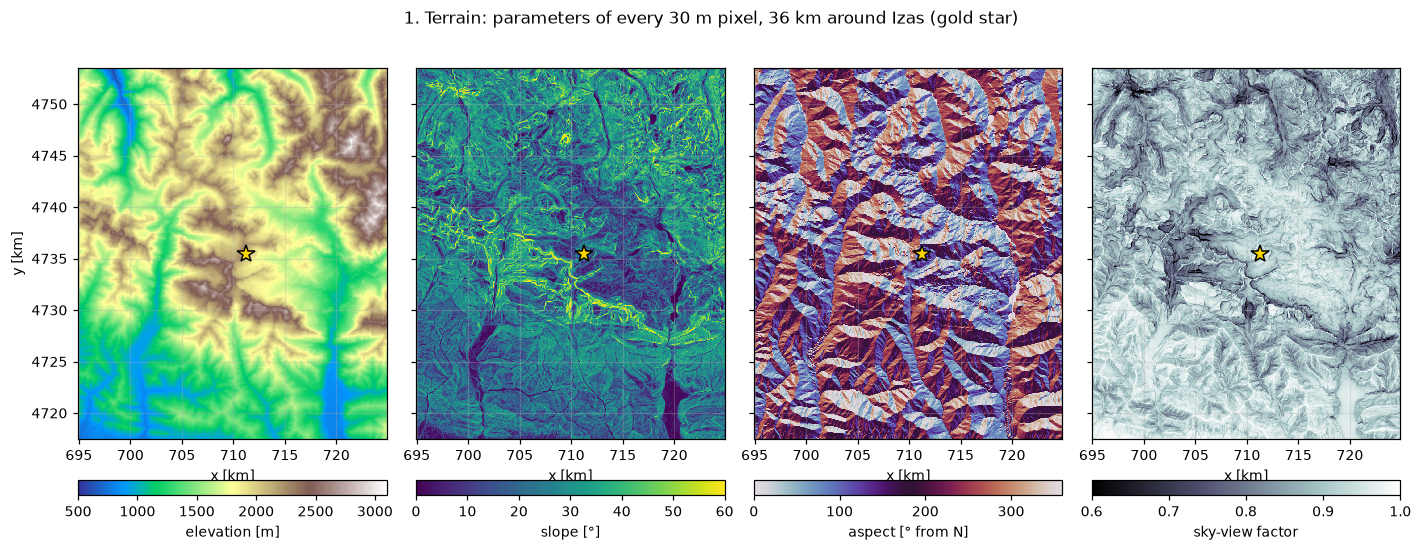

In [6]:
######################################################################################################################
# Figure: terrain parameters around Izas
tz = ds_param.sel(x=slice(zoom[0], zoom[2]), y=slice(zoom[3], zoom[1]))
ext = [km(tz.x[0]), km(tz.x[-1]), km(tz.y[-1]), km(tz.y[0])]
layers = [(tz.elevation, "terrain", "elevation [m]", 500, 3100),
          (np.rad2deg(tz.slope), "viridis", "slope [°]", 0, 60),
          (pu.compass_aspect(tz.aspect), "twilight", "aspect [° from N]", 0, 360),
          (tz.svf, "bone", "sky-view factor", 0.6, 1.0)]
fig, axs = plt.subplots(1, 4, figsize=(13, 5.2), sharey=True)
for ax, (v, cmap, lab, vmin, vmax) in zip(axs, layers):
    im = ax.imshow(v, cmap=cmap, vmin=vmin, vmax=vmax, extent=ext, interpolation="nearest")
    plt.colorbar(im, ax=ax, orientation="horizontal", pad=0.08, label=lab)
    ax.plot(km(x_izas), km(y_izas), "*", color="gold", mec="k", ms=12)
    ax.set_xlabel("x [km]")
axs[0].set_ylabel("y [km]")
fig.suptitle("1. Terrain: parameters of every 30 m pixel, 36 km around Izas (gold star)")
plt.tight_layout()
plt.show()

## 2. TopoSUB

Downscaling 4.6 million pixels one by one would be slow and produce huge files. TopoSUB groups pixels with similar
terrain into **clusters** (k-means on x, y, elevation, slope, aspect and SVF, with elevation weighted ×4) and
downscales only one point per cluster, its **centroid**, which has the mean parameters of the cluster's pixels.
`extract_topo_param()` writes the centroids to `df_centroids.pck` and the cluster of every pixel to `ds_param.nc`.
These cluster labels map the results of step 5 back onto the pixels.

More clusters represent the terrain more closely, at a cost that grows linearly with their number in step 5.

In [7]:
######################################################################################################################
# TopoPyScale processing: step 2, clustering of the transect
cent = {}
for n in RUNS:
    with timed(f"2. TopoSUB: {n} clusters", cached=(PROJ[n] / "outputs" / "df_centroids.pck").exists()):
        mp[n].extract_topo_param()
    cent[n] = pu.centroid_table(mp[n])                       # centroids, plus aspect in degrees and northness
ds_param = mp[N].toposub.ds_param                            # terrain parameters + cluster labels of the main run
n_pix = int((np.asarray(ds_param.point_ind.values) >= 0).sum())
for n in RUNS:
    print(f"{n_pix / 1e6:.1f} million pixels -> {n} clusters: {n_pix / n:,.0f} pixels per cluster")
cent[N][["elevation", "slope_deg", "aspect_deg", "svf", "lat", "lon"]].describe().round(2)

---> Centroids file df_centroids.pck exists and loaded
[2. TopoSUB: 300 clusters] loaded from disk in 0 s (computed in 7.3 min)
---> Centroids file df_centroids.pck exists and loaded
[2. TopoSUB: 3000 clusters] loaded from disk in 0 s (computed in 2.6 min)
4.6 million pixels -> 300 clusters: 15,423 pixels per cluster
4.6 million pixels -> 3000 clusters: 1,542 pixels per cluster


,elevation,slope_deg,aspect_deg,svf,lat,lon
count,3000.00,3000.00,3000.00,3000.00,3000.00,3000.00
mean,1091.84,18.96,182.20,0.91,42.73,-0.44
std,597.46,12.29,103.25,0.07,0.33,0.10
min,136.64,0.24,0.12,0.50,42.12,-0.62
25%,615.74,8.90,92.27,0.87,42.43,-0.53
50%,1020.94,17.72,186.99,0.93,42.78,-0.44
75%,1487.77,28.22,267.31,0.98,43.00,-0.34
max,2912.98,60.77,359.94,1.00,43.33,-0.24


Around Izas: the elevation of each cluster painted on its pixels, and the cluster membership (random colours).

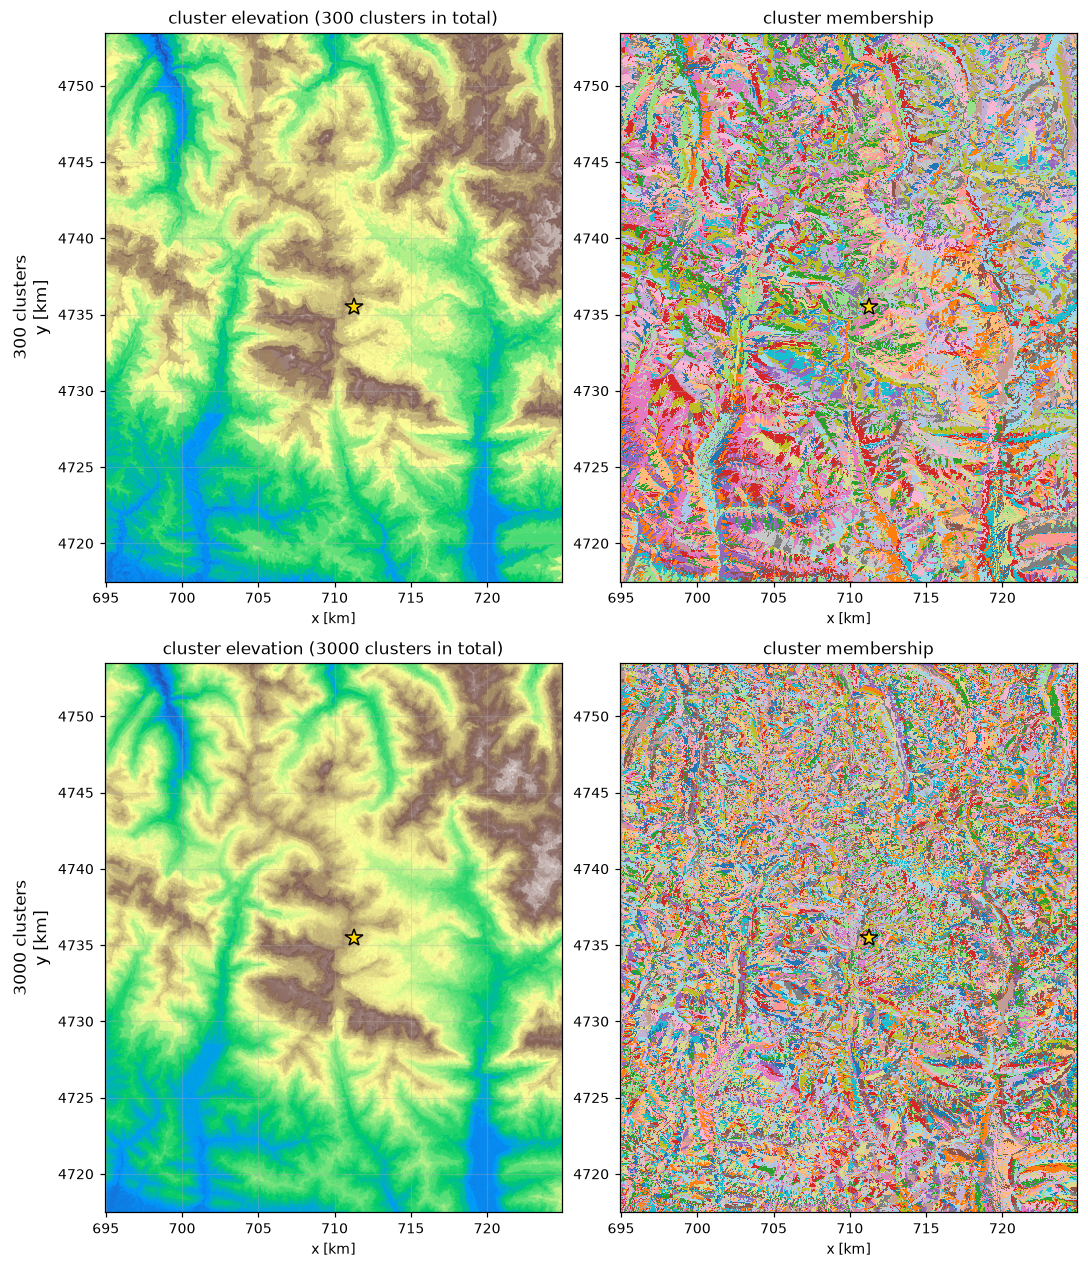

In [8]:
######################################################################################################################
# Figure: the clusters around Izas, one row per run
fig, axs = plt.subplots(len(RUNS), 2, figsize=(10, 5.8 * len(RUNS)), squeeze=False)
for row, n in zip(axs, RUNS):
    p_ = mp[n].toposub.ds_param.sel(x=slice(zoom[0], zoom[2]), y=slice(zoom[3], zoom[1]))
    ext = [km(p_.x[0]), km(p_.x[-1]), km(p_.y[-1]), km(p_.y[0])]
    shuffle = pd.Series(np.random.default_rng(0).permutation(n), index=cent[n].index)
    row[0].imshow(pu.to_grid(cent[n].elevation, p_), cmap="terrain", vmin=500, vmax=3100, extent=ext)
    row[0].set_title(f"cluster elevation ({n} clusters in total)")
    row[1].imshow(pu.to_grid(shuffle, p_), cmap="tab20", extent=ext, interpolation="nearest")
    row[1].set_title("cluster membership")
    for a in row:
        a.plot(km(x_izas), km(y_izas), "*", color="gold", mec="k", ms=12)
        a.set_xlabel("x [km]")
    row[0].set_ylabel(f"{n} clusters\ny [km]", fontsize=11)
plt.tight_layout()
plt.show()

### 2. TopoSUB, or a list of points: the Izas weather station

Instead of clusters, TopoPyScale can downscale a list of points given in a CSV file (`sampling: method: points`). Steps 3–5 are then the same. For the station comparison we use this **points mode** on a 24 × 24 km window of the same 30 m DEM.
Besides the AWS itself we add two sets of additional points around Izas:

* an **elevation series**: gentle-slope points from the valley floor to the summits (~200 m apart), and
* an **aspect rose**: 8 slopes at the station's elevation facing N, NE, …, NW.

> **Station position.** Izas AWS at 42.74268°N, 0.41912°W, 2113 m a.s.l. (station metadata, `pyr_utils.IZAS`).
> TopoPyScale uses the DEM elevation of the pixel (printed below), which is a few tens of metres lower; the
> observed pressure gives an independent check of the station elevation (notebook 2, section 6b). Note that the rounded value
> often quoted for the catchment (42°44′N, 0°25′W) is ~1 km away, on a steep south-east-facing slope: precise
> station coordinates matter at this scale.

In [9]:
######################################################################################################################
# TopoPyScale processing: step 2 for a list of points (station, elevation series, aspect rose)
pts = pu.izas_point_table(mp_i.toposub.ds_param)            # points picked on the Izas DEM (step 1)
pts[["name", "x", "y"]].to_csv(PROJ_I / "inputs" / "dem" / "izas_points.csv", index=False)
old = PROJ_I / "outputs" / "df_centroids.pck"                # points changed -> recompute the point outputs
if old.exists() and set(pd.read_pickle(old).point_name) != set(pts.name):
    for f in ("df_centroids.pck", "ds_solar.nc"):
        (PROJ_I / "outputs" / f).unlink(missing_ok=True)
    for f in (PROJ_I / "outputs" / "downscaled").glob("down_pt_*.nc"):
        f.unlink()
with timed("2. TopoSUB: Izas points", cached=old.exists()):
    mp_i.extract_topo_param()
pt_info = pu.izas_point_info(mp_i)                           # DEM parameters + group of each point
z_izas = float(pt_info.loc["Izas_AWS", "elevation"])
r = pt_info.loc["Izas_AWS"]
print(f"Izas AWS in the DEM: elevation {r.elevation:.0f} m (station {pu.IZAS['elev']:.0f} m), slope {r.slope_deg:.1f}°, "
      f"aspect {r.aspect_deg:.0f}°, SVF {r.svf:.2f}")
pt_info[["group", "elevation", "slope_deg", "aspect_deg", "svf"]].round(2)

---> Centroids file df_centroids.pck exists and loaded
[2. TopoSUB: Izas points] loaded from disk in 0 s (computed in 0.0 min)
Izas AWS in the DEM: elevation 2073 m (station 2113 m), slope 6.2°, aspect 44°, SVF 0.96


,group,elevation,slope_deg,aspect_deg,svf
point_name,,,,,
Izas_AWS,station,2073.01,6.20,43.81,0.96
elev_1400,elevation_series,1439.71,4.89,97.30,0.90
elev_1600,elevation_series,1629.04,0.73,131.79,0.96
elev_1800,elevation_series,1820.56,1.39,5.45,0.95
elev_2000,elevation_series,2020.78,0.66,326.75,0.97
elev_2200,elevation_series,2192.70,0.51,243.70,0.99
elev_2400,elevation_series,2384.22,2.99,7.21,1.00
elev_2600,elevation_series,2564.85,3.79,159.59,0.95
elev_2800,elevation_series,2782.48,22.48,19.88,0.95


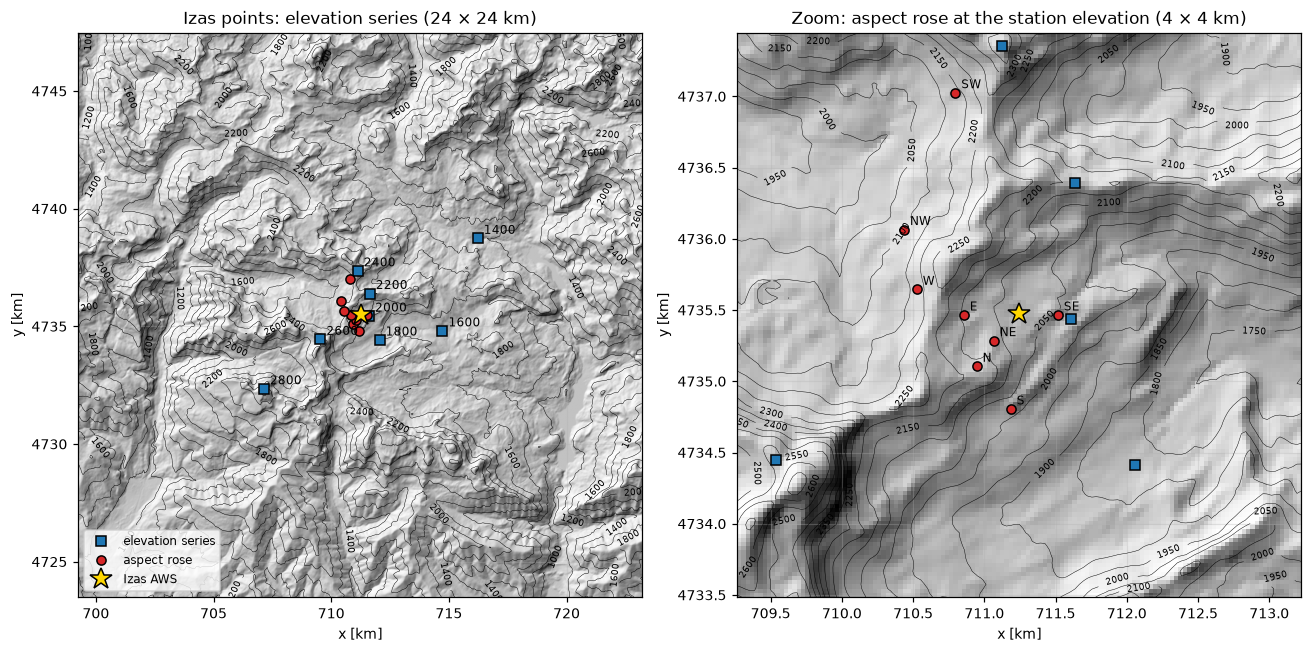

In [10]:
######################################################################################################################
# Figure: the Izas points
win = xr.open_dataarray(DEM_IZAS, engine="rasterio").squeeze("band", drop=True)
fig, axs = plt.subplots(1, 2, figsize=(12, 6))
for ax, half, step in ((axs[0], 12e3, 200), (axs[1], 2e3, 50)):
    w = win.sel(x=slice(x_izas - half, x_izas + half), y=slice(y_izas + half, y_izas - half))
    e = [km(w.x[0]), km(w.x[-1]), km(w.y[-1]), km(w.y[0])]
    ax.imshow(pu.hillshade(w.values, DEM_RES), cmap="gray", extent=e)
    cs = ax.contour(km(w.x), km(w.y), w.values, levels=np.arange(1000, 3200, step), colors="k", linewidths=0.3)
    ax.clabel(cs, fontsize=6)
    for g, mk, c in (("elevation_series", "s", "tab:blue"), ("aspect_rose", "o", "tab:red")):
        p = pt_info[(pt_info.group == g) & (abs(pt_info.x - x_izas) < half) & (abs(pt_info.y - y_izas) < half)]
        ax.plot(km(p.x), km(p.y), mk, color=c, mec="k", label=g.replace("_", " "))
        if (g == "aspect_rose") == (half < 5e3):   # label the rose in the zoom, the elevation series in the overview
            for n, r in p.iterrows():
                ax.annotate(n.split("_")[-1], (km(r.x), km(r.y)), xytext=(4, 3), textcoords="offset points", fontsize=8)
    ax.plot(km(x_izas), km(y_izas), "*", color="gold", mec="k", ms=15, label="Izas AWS")
    ax.set(xlabel="x [km]", ylabel="y [km]")
axs[0].legend(loc="lower left", fontsize=8)
axs[0].set_title("Izas points: elevation series (24 × 24 km)")
axs[1].set_title("Zoom: aspect rose at the station elevation (4 × 4 km)")
plt.tight_layout()
plt.show()

## 3. Solar geometry

`compute_solar_geometry()` computes the position of the sun (elevation and azimuth), the cosine of the solar zenith
angle and the top-of-atmosphere shortwave for every cluster (or point) and time step → `ds_solar.nc`. It is cheap.
Step 5 uses it to split ERA5's shortwave into direct and diffuse, and to project the direct beam onto each slope.

In [11]:
######################################################################################################################
# TopoPyScale processing: step 3, solar geometry
for n in RUNS:
    with timed(f"3. Solar geometry: {n} clusters{TAG}", cached=(PROJ[n] / "outputs" / "ds_solar.nc").exists()):
        mp[n].compute_solar_geometry()
with timed(f"3. Solar geometry: Izas points{TAG}", cached=(PROJ_I / "outputs" / "ds_solar.nc").exists()):
    mp_i.compute_solar_geometry()
sun = mp_i.ds_solar.sel(point_name="Izas_AWS", time=T_EX)
print(f"Izas AWS, {T_EX:%Y-%m-%d %H} UTC: sun elevation {np.rad2deg(float(sun.elevation)):.0f}°, "
      f"top-of-atmosphere shortwave {float(sun.SWtoa):.0f} W m-2")

---> Solar file ds_solar.nc exists and loaded
[3. Solar geometry: 300 clusters] loaded from disk in 0 s (computed in 0.1 min)
---> Solar file ds_solar.nc exists and loaded
[3. Solar geometry: 3000 clusters] loaded from disk in 0 s (computed in 1.5 min)
---> Solar file ds_solar.nc exists and loaded
[3. Solar geometry: Izas points] loaded from disk in 0 s (computed in 0.0 min)
Izas AWS, 2019-01-24 12 UTC: sun elevation 28°, top-of-atmosphere shortwave 642 W m-2


## 4. Horizons

`compute_horizon()` computes, for every pixel of the DEM, the **horizon angle** in 36 directions (every 10°), i.e.
how high the surrounding terrain rises above the pixel → `da_horizon.nc`. It then reads the 36 angles at the pixel
nearest to each cluster centroid (or point). In step 5, when the sun is lower than that horizon in its direction,
the cluster is in a **cast shadow** and only gets diffuse radiation: the shadow of a whole cluster is decided by this
one pixel. Like step 1 this works on the DEM and is computed once (~26 min); the 3000-cluster project links
the file of the 300-cluster one.

The figure shows the horizon of the Izas AWS with the path of the sun on the solstices and the equinox: when the sun
is below the local horizon, only diffuse radiation reaches the station. The dots are the sun at the ERA5 time steps: 06, 12 and 18 UTC with 6-hourly data, every hour with hourly data.

In [12]:
######################################################################################################################
# TopoPyScale processing: step 4, horizons
for n in RUNS:
    with timed(f"4. Horizons: {n} clusters", cached=(PROJ[n] / "outputs" / "da_horizon.nc").exists()):
        mp[n].compute_horizon()                              # on the DEM once, then sampled at the centroids
with timed("4. Horizons: Izas points", cached=(PROJ_I / "outputs" / "da_horizon.nc").exists()):
    mp_i.compute_horizon()

---> Horizon file da_horizon.nc exists and loaded


---> Centroids file df_centroids.pck updated with horizons
[4. Horizons: 300 clusters] loaded from disk in 3 s (computed in 26.0 min)
---> Horizon file da_horizon.nc exists and loaded


---> Centroids file df_centroids.pck updated with horizons
[4. Horizons: 3000 clusters] loaded from disk in 5 s (computed in 0.1 min)
---> Horizon file da_horizon.nc exists and loaded


---> Centroids file df_centroids.pck updated with horizons
[4. Horizons: Izas points] loaded from disk in 0 s (computed in 0.5 min)


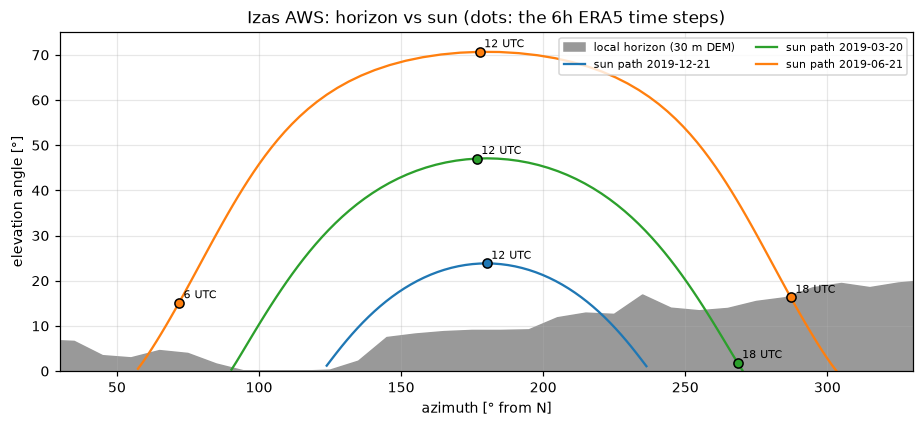

In [13]:
######################################################################################################################
# Figure: horizon and sun path at the Izas AWS
import pvlib

step_h = {"6h": 6, "1h": 1}[ERA5_TIMESTEP]           # ERA5 time steps: every 6 h or every hour
hz = mp_i.da_horizon.sel(x=x_izas, y=y_izas, method="nearest")
hz_az = np.mod(180 - hz.azimuth.values, 360)          # TopoPyScale/topocalc azimuth: 0 = South, +East
order = np.argsort(hz_az)
fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(np.r_[hz_az[order], hz_az[order][0] + 360], 0, np.rad2deg(np.r_[hz.values[order], hz.values[order][0]]),
                color="0.6", label="local horizon (30 m DEM)")
for day, c in (("2019-12-21", "tab:blue"), ("2019-03-20", "tab:green"), ("2019-06-21", "tab:orange")):
    tday = pd.date_range(day, periods=24 * 6, freq="10min", tz="UTC")
    sp = pvlib.solarposition.get_solarposition(tday, pu.IZAS["lat"], pu.IZAS["lon"], altitude=z_izas)
    up = sp.apparent_elevation > 0
    ax.plot(sp.azimuth[up], sp.apparent_elevation[up], color=c, label=f"sun path {day}")
    for h in range(0, 24, step_h):                    # the sun at the ERA5 time steps
        s = sp[sp.index.hour == h].iloc[:1]
        if float(s.apparent_elevation.iloc[0]) > 0:
            ax.plot(s.azimuth, s.apparent_elevation, "o", color=c, mec="k", ms=6 if step_h > 1 else 4)
            if h % 3 == 0:                                # label every 3 h (every time step with 6-hourly data)
                ax.annotate(f"{h} UTC", (float(s.azimuth.iloc[0]), float(s.apparent_elevation.iloc[0])), fontsize=7,
                            xytext=(3, 3), textcoords="offset points")
ax.set(xlim=(30, 330), ylim=(0, 75), xlabel="azimuth [° from N]", ylabel="elevation angle [°]",
       title=f"Izas AWS: horizon vs sun (dots: the {ERA5_TIMESTEP} ERA5 time steps)")
ax.legend(fontsize=7, ncol=2)
plt.show()

## 5. TopoScale

`downscale_climate()` produces one time series per cluster (or point) → `outputs/downscaled/down_pt_<name>.nc`.
For each cluster:

* **horizontal**: the 3 × 3 ERA5 cells around it are averaged with inverse-distance weights;
* **vertical**: temperature, humidity and wind are interpolated in the ERA5 pressure-level profile to the cluster
  elevation, pressure is computed hypsometrically, and precipitation is scaled with an elevation-dependent factor;
* **radiation**: shortwave is split into direct and diffuse; the diffuse part is scaled by the sky-view factor, and
  the direct beam is projected onto the slope and removed in cast shadows; longwave is corrected for the sky view
  and the emission of the surrounding terrain.

With ERA5 in zarr this takes about 0.1–0.2 s per cluster.

In [14]:
######################################################################################################################
# TopoPyScale processing: step 5, downscaling
down = {}
for n in RUNS:
    done = len(list((PROJ[n] / "outputs" / "downscaled").glob("down_pt_*.nc"))) == n
    with timed(f"5. TopoScale: {n} clusters{TAG}", cached=done):
        if not done:
            mp[n].downscale_climate()
        down[n] = pu.load_results(mp[n])                     # read the outputs (faster than mp.load_project())
done = len(list((PROJ_I / "outputs" / "downscaled").glob("down_pt_*.nc"))) == len(pts)
with timed(f"5. TopoScale: Izas points{TAG}", cached=done):
    if not done:
        mp_i.downscale_climate()
    dsi = pu.load_results(mp_i)
down[N]                                                      # the downscaled dataset: variables per cluster and time

[5. TopoScale: 300 clusters] loaded from disk in 17 s (computed in 0.8 min)


[5. TopoScale: 3000 clusters] loaded from disk in 68 s (computed in 4.4 min)


[5. TopoScale: Izas points] loaded from disk in 0 s (computed in 0.2 min)


<xarray.Dataset> Size: 1GB
Dimensions:            (point_name: 3000, time: 2924)
Coordinates:
  * point_name         (point_name) <U4 48kB '0000' '0001' ... '2998' '2999'
    point_ind          (point_name) int64 24kB 0 1 2 3 4 ... 2996 2997 2998 2999
  * time               (time) datetime64[ns] 23kB 2019-01-01 ... 2020-12-31T1...
Data variables: (12/17)
    t                  (point_name, time) float64 70MB 286.4 284.5 ... 272.3
    u                  (point_name, time) float64 70MB -0.1296 -0.3557 ... 3.055
    v                  (point_name, time) float64 70MB -0.8145 -1.11 ... 1.173
    q                  (point_name, time) float64 70MB 0.002679 ... 0.00371
    p                  (point_name, time) float64 70MB 9.187e+04 ... 8.557e+04
    precip_lapse_rate  (point_name, time) float64 70MB 1.015 1.015 ... 1.102
    ...                 ...
    cse                (point_name, time) float64 70MB 0.685 0.6738 ... 0.7099
    LW                 (point_name, time) float64 70MB 277.3 269.0 ... 282.0
    SW_diffuse         (point_name, time) float64 70MB 0.0 0.0 ... 90.88 0.0
    cos_illumination   (point_name, time) float64 70MB 0.09764 -0.0 ... 0.2795
    SW_direct          (point_name, time) float64 70MB 0.0 0.0 105.6 ... 0.0 0.0
    SW                 (point_name, time) float64 70MB 0.0 0.0 ... 90.88 0.0
Attributes:
    title:            Downscaled timeseries with TopoPyScale
    created with:     TopoPyScale, see more at https://topopyscale.readthedoc...
    package_version:  0.3.3
    git_commit:       cc8b8ca5ad48e839785f83c1665aec542db703a7
    url_TopoPyScale:  https://github.com/ArcticSnow/TopoPyScale
    date_created:     2026-11-12 17:33:52

### A downscaled field

Shortwave at `T_EX`, a clear winter noon. ERA5 has one value per grid cell; TopoPyScale has one value per cluster,
painted on the cluster's pixels. With more clusters the map follows slopes and valleys more closely. The table compares
the runs.

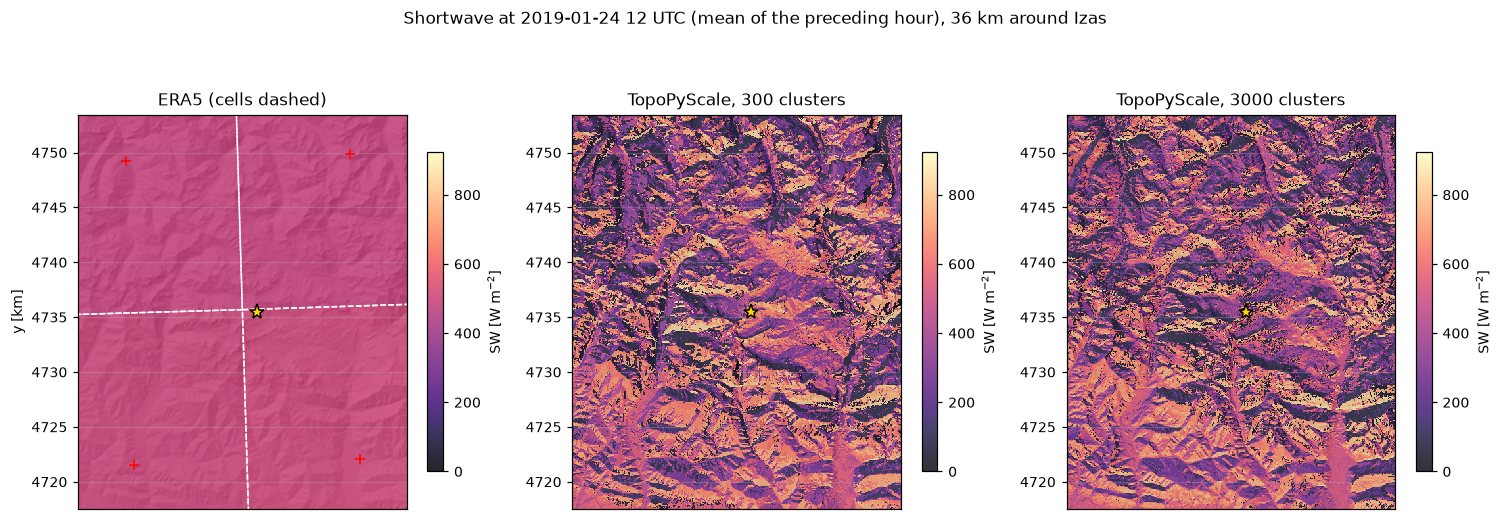

In [15]:
######################################################################################################################
# Figure: shortwave at T_EX, ERA5 and the cluster runs
surf = pu.open_era5_surf(CLIM).sel(time=T_EX).load()
zp = {n: mp[n].toposub.ds_param.sel(x=slice(zoom[0], zoom[2]), y=slice(zoom[3], zoom[1])) for n in RUNS}
gx, gy = zp[N].x.values[::2], zp[N].y.values[::2]
e = [km(gx[0]), km(gx[-1]), km(gy[-1]), km(gy[0])]
snaps = {n: down[n].SW.sel(time=T_EX).load().to_series() for n in RUNS}
vmax = max(float(s.max()) for s in snaps.values())
fig, axs = plt.subplots(1, 1 + len(RUNS), figsize=(4.6 * (1 + len(RUNS)), 5.4))
axs[0].imshow(pu.hillshade(dem.sel(x=gx, y=gy, method="nearest").values, DEM_RES * 2), cmap="gray", extent=e)
im = axs[0].imshow(pu.era5_display_map(surf.ssrd / 3600, gx, gy), cmap="magma", vmin=0, vmax=vmax, alpha=0.85,
                   extent=e)
pu.draw_era5_cells(axs[0], pu.era5_cells_in(surf.z, (zoom[0] - 15e3, zoom[1] - 15e3, zoom[2] + 15e3, zoom[3] + 15e3)),
                   ec="w", lw=1, ls="--")
axs[0].plot(km(x_izas), km(y_izas), "*", color="gold", mec="k", ms=10)
axs[0].set(xlim=e[:2], ylim=e[2:], xticks=[], ylabel="y [km]", title="ERA5 (cells dashed)")
fig.colorbar(im, ax=axs[0], shrink=0.6, label="SW [W m$^{-2}$]")
for ax, n in zip(axs[1:], RUNS):
    pu.map_clusters(ax, snaps[n], "magma", "SW [W m$^{-2}$]", 0, vmax, stride=2, params=zp[n], dem=dem)
    ax.set_title(f"TopoPyScale, {n} clusters")
fig.suptitle(f"Shortwave at {T_EX:%Y-%m-%d %H} UTC (mean of the preceding hour), 36 km around Izas")
plt.tight_layout()
plt.show()

In [16]:
######################################################################################################################
# Table: the cluster runs
TIMES = pu.load_times(TIMES_FILE)
stats = {}
for n in RUNS:
    p_ = mp[n].toposub.ds_param
    dz = pu.to_grid(cent[n].elevation, p_, stride=3).values - p_.elevation.values[::3, ::3]
    pid_n = str(p_.point_name.sel(x=x_izas, y=y_izas, method="nearest").item())
    stats[f"{n} clusters"] = {
        "pixels per cluster": n_pix / n,
        "mean |cluster - pixel elevation| [m]": np.nanmean(np.abs(dz)),
        "elevation of the cluster containing Izas AWS [m]": cent[n].loc[pid_n, "elevation"],
        "2. TopoSUB [min]": TIMES.get(f"2. TopoSUB: {n} clusters", np.nan) / 60,
        "5. TopoScale [min]": TIMES.get(f"5. TopoScale: {n} clusters{TAG}", np.nan) / 60,
        "downscaled files [MB]": pu.disk_usage(PROJ[n] / "outputs" / "downscaled") / 1e6,
    }
print(f"Izas AWS: station {pu.IZAS['elev']:.0f} m, DEM pixel {float(dem.sel(x=x_izas, y=y_izas, method='nearest')):.0f} m")
pd.DataFrame(stats).round(1)

Izas AWS: station 2113 m, DEM pixel 2072 m


,300 clusters,3000 clusters
pixels per cluster,15423.3,1542.3
mean |cluster - pixel elevation| [m],52.5,31.2
elevation of the cluster containing Izas AWS [m],2017.9,2108.7
2. TopoSUB [min],7.3,2.6
5. TopoScale [min],0.8,4.4
downscaled files [MB],116.9,1171.5


### Inside step 5: partial results around Izas

TopoPyScale does the following for **every cluster of the transect**. Here we zoom on Izas at one time step (`T_EX`)
and show the intermediate results for the main run (3000 clusters in full mode).

* **(a) Horizontal.** Each cluster takes the 3 × 3 ERA5 cells around its nearest cell, weighted by inverse squared
  distance. Shown: the weights for the cluster that contains the Izas AWS (orange dot); the black rectangle is the
  transect, the dashed one the zoom of the other maps.
* **(b) Vertical.** The weighted pressure-level profile (black) is interpolated linearly to the cluster elevation.
  All clusters around Izas (blue) fall on it, whereas ERA5's own 2 m temperature (red squares) sits at the smooth
  model orography. Humidity and wind are interpolated the same way; pressure is computed hypsometrically.
* **(d–g) Shortwave.** The ERA5 value (d) is split into diffuse and direct with an empirical clearness-index
  relation. The diffuse part is scaled by the sky-view factor (e). The direct part is multiplied by the factor
  cos *i* / cos *z* (f: the illumination angle on the slope relative to a flat surface).
  The factor is above 1 on slopes facing the sun, 0 on slopes facing away, and black where the horizon casts a
  shadow. (g) is the sum.

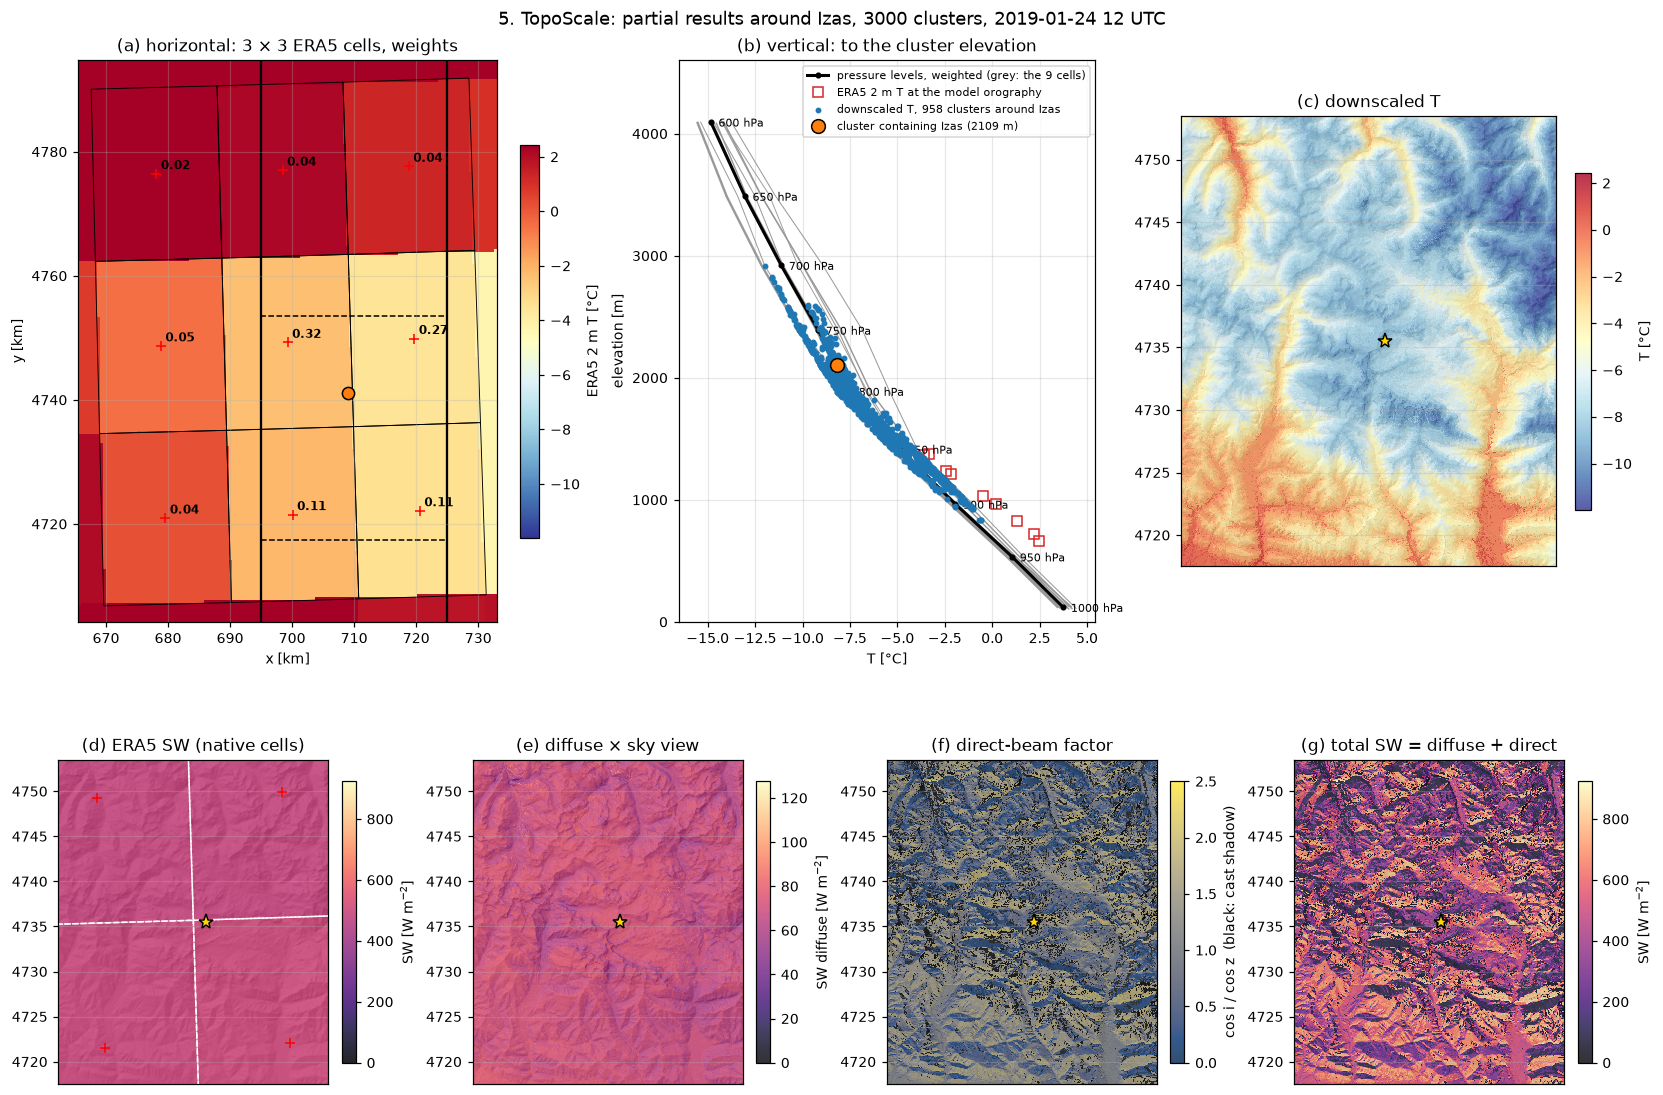

Cluster 0593 (2109 m, slope 10°, aspect 62°, SVF 0.95): T -8.2 °C (nearest ERA5 cell -2.4 °C); SW: ERA5 486 -> diffuse 78 + direct 344 = 421 W m-2


In [17]:
######################################################################################################################
# Partial results: horizontal and vertical interpolation for the cluster containing Izas
pid = str(ds_param.point_name.sel(x=x_izas, y=y_izas, method="nearest").item())
c = cent[N].loc[pid]
plev = pu.open_era5_plev(CLIM).sel(time=T_EX).load()
w = pu.toposcale_weights(c.lat, c.lon, c.x, c.y, surf.latitude.values, surf.longitude.values)
cells = plev.sel(latitude=w.latitude, longitude=w.longitude)
prof = (cells[["t", "z"]] * w).sum(["latitude", "longitude"])   # weighted pressure-level profile
z_prof, t_prof = prof.z.values / 9.81, prof.t.values - 273.15    # TopoPyScale uses g = 9.81 here
snap = down[N].sel(time=T_EX).load()
t_izas = float(snap.t.sel(point_name=pid)) - 273.15
o = np.argsort(z_prof)
assert abs(np.interp(c.elevation, z_prof[o], t_prof[o]) - t_izas) < 0.05, "T is not the interpolated profile"

######################################################################################################################
# Figure: partial results around Izas
near = cent[N][cent[N].x.between(zoom[0], zoom[2]) & cent[N].y.between(zoom[1], zoom[3])]
t_near = snap.t.sel(point_name=near.index.values).to_series() - 273.15
t2m_cells = surf.t2m.sel(latitude=w.latitude, longitude=w.longitude) - 273.15
oro_cells = surf.z.sel(latitude=w.latitude, longitude=w.longitude) / pu.G
tlim = (float(min(t_near.min(), t2m_cells.min())), float(max(t_near.max(), t2m_cells.max())))

fig = plt.figure(figsize=(15, 10.5), layout="constrained")
top, bot = fig.subfigures(2, 1, height_ratios=[1.2, 0.9])
ax = top.subplots(1, 3, width_ratios=[1.1, 1, 0.9])
# (a) horizontal: the 3 x 3 ERA5 cells and their weights
lo_, la_ = w.longitude.values, w.latitude.values
cx, cy = pu.to_utm.transform([lo_.min() - .15, lo_.max() + .15] * 2, [la_.min() - .15] * 2 + [la_.max() + .15] * 2)
hx, hy = np.arange(min(cx), max(cx), 500.0), np.arange(max(cy), min(cy), -500.0)
he = [km(hx[0]), km(hx[-1]), km(hy[-1]), km(hy[0])]
im = ax[0].imshow(pu.era5_display_map(surf.t2m - 273.15, hx, hy), cmap="RdYlBu_r", vmin=tlim[0], vmax=tlim[1], extent=he)
top.colorbar(im, ax=ax[0], shrink=0.7, label="ERA5 2 m T [°C]")
pu.draw_era5_cells(ax[0], [(la, lo) for la in la_ for lo in lo_], ec="k", lw=0.6)
for la in la_:
    for lo in lo_:
        xc, yc = pu.to_utm.transform(lo, la)
        ax[0].annotate(f"{float(w.sel(latitude=la, longitude=lo)):.2f}", (km(xc), km(yc)), xytext=(3, 3),
                       textcoords="offset points", fontsize=8, weight="bold")
ax[0].add_patch(Rectangle((km(tb[0]), km(tb[1])), km(tb[2] - tb[0]), km(tb[3] - tb[1]), fill=False, ec="k", lw=1.5))
ax[0].add_patch(Rectangle((km(zoom[0]), km(zoom[1])), km(zoom[2] - zoom[0]), km(zoom[3] - zoom[1]), fill=False,
                          ec="k", ls="--"))
ax[0].plot(km(c.x), km(c.y), "o", color="tab:orange", mec="k", ms=8)
ax[0].set(xlim=he[:2], ylim=he[2:], xlabel="x [km]", ylabel="y [km]", title="(a) horizontal: 3 × 3 ERA5 cells, weights")
# (b) vertical: interpolation in the pressure-level profile
for la in la_:
    for lo in lo_:
        cc = cells.sel(latitude=la, longitude=lo)
        ax[1].plot(cc.t - 273.15, cc.z / 9.81, color="0.6", lw=0.5 + 4 * float(w.sel(latitude=la, longitude=lo)))
ax[1].plot(t_prof, z_prof, "k-o", ms=3, lw=2, label="pressure levels, weighted (grey: the 9 cells)")
for lev, tt, zz in zip(prof.level.values, t_prof, z_prof):
    ax[1].annotate(f"{lev:.0f} hPa", (tt, zz), xytext=(5, -3), textcoords="offset points", fontsize=7)
ax[1].plot(t2m_cells.values.ravel(), oro_cells.values.ravel(), "s", color="tab:red", mfc="none", ms=7,
           label="ERA5 2 m T at the model orography")
ax[1].scatter(t_near, near.elevation, s=8, color="tab:blue", zorder=3,
              label=f"downscaled T, {len(near)} clusters around Izas")
ax[1].plot(t_izas, c.elevation, "o", color="tab:orange", mec="k", ms=9, zorder=4,
           label=f"cluster containing Izas ({c.elevation:.0f} m)")
ax[1].set(xlabel="T [°C]", ylabel="elevation [m]", ylim=(0, 4600), title="(b) vertical: to the cluster elevation")
ax[1].legend(fontsize=7, loc="upper right")
# (c) result
pu.map_clusters(ax[2], snap.t.to_series() - 273.15, "RdYlBu_r", "T [°C]", *tlim, stride=2, params=zp[N], dem=dem)
ax[2].set_title("(c) downscaled T")

# shortwave
sw, dif, dirr = (snap[v].to_series() for v in ("SW", "SW_diffuse", "SW_direct"))
cosi = snap.cos_illumination.to_series()
mu0 = mp[N].ds_solar.mu0.sel(time=T_EX).load().to_series().reindex(cosi.index)
factor = cosi / mu0
factor[(cosi > 0) & (dirr <= 0)] = -1                           # sun above the slope but behind the horizon
cm_f = plt.get_cmap("cividis").copy()
cm_f.set_under("k")
bx = bot.subplots(1, 4)
bx[0].imshow(pu.hillshade(dem.sel(x=gx, y=gy, method="nearest").values, DEM_RES * 2), cmap="gray", extent=e)
im = bx[0].imshow(pu.era5_display_map(surf.ssrd / 3600, gx, gy), cmap="magma", vmin=0, vmax=vmax, alpha=0.85, extent=e)
pu.draw_era5_cells(bx[0], pu.era5_cells_in(surf.z, (zoom[0] - 15e3, zoom[1] - 15e3, zoom[2] + 15e3, zoom[3] + 15e3)),
                   ec="w", lw=1, ls="--")
bot.colorbar(im, ax=bx[0], shrink=0.6, label="SW [W m$^{-2}$]")
bx[0].plot(km(x_izas), km(y_izas), "*", color="gold", mec="k", ms=10)
bx[0].set(xlim=e[:2], ylim=e[2:], xticks=[], title="(d) ERA5 SW (native cells)")
pu.map_clusters(bx[1], dif, "magma", "SW diffuse [W m$^{-2}$]", 0, float(dif.max()), stride=2, params=zp[N], dem=dem)
bx[1].set_title("(e) diffuse × sky view")
pu.map_clusters(bx[2], factor, cm_f, "cos i / cos z  (black: cast shadow)", 0, 2.5, stride=2, params=zp[N], dem=dem)
bx[2].set_title("(f) direct-beam factor")
pu.map_clusters(bx[3], sw, "magma", "SW [W m$^{-2}$]", 0, vmax, stride=2, params=zp[N], dem=dem)
bx[3].set_title("(g) total SW = diffuse + direct")
fig.suptitle(f"5. TopoScale: partial results around Izas, {N} clusters, {T_EX:%Y-%m-%d %H} UTC", fontsize=12)
plt.show()

sw_era = float((surf.ssrd / 3600).sel(latitude=w.latitude, longitude=w.longitude).weighted(w).sum())
print(f"Cluster {pid} ({c.elevation:.0f} m, slope {c.slope_deg:.0f}°, aspect {c.aspect_deg:.0f}°, SVF {c.svf:.2f}): "
      f"T {t_izas:.1f} °C (nearest ERA5 cell {float(surf.t2m.sel(latitude=c.lat, longitude=c.lon, method='nearest')) - 273.15:.1f} °C); "
      f"SW: ERA5 {sw_era:.0f} -> diffuse {dif[pid]:.0f} + direct {dirr[pid]:.0f} = {sw[pid]:.0f} W m-2")

## Results

Each project now has one time series per cluster (or point) in `outputs/downscaled/`. Notebook 2 maps them back onto
the pixels with the cluster labels, analyses the gradients, validates them at the Izas AWS and drives the FSM snow
model with them.

**What TopoPyScale adds to ERA5 here** (the evidence is in notebook 2, from the 6-hourly run)

* **Elevation.** ERA5's Pyrenees peak at ~1400 m, while the real summits along the transect reach ~3000 m.
  TopoPyScale brings temperature, humidity and pressure to the real elevation of every slope. At Izas (2113 m,
  ~700 m above its ERA5 cell) the temperature bias drops from +3.5 °C to +0.4 °C (RMSE 4.9 → 1.9 °C), the pressure
  bias from +77 hPa to +6 hPa (mostly the DEM pixel being ~40 m below the station), and the RH correlation rises
  from 0.53 to 0.86. The observed temperatures fall on the downscaled elevation profile.
* **N–S climate.** The large-scale contrast of ERA5 (wetter and cloudier Atlantic side, sunnier south) is kept and
  combined with the local topography; at the same elevation the northern slopes are wetter and get less noon sun.
* **Terrain and radiation.** Aspect, slope, cast shadows and sky view turn one ERA5 value into strongly contrasting
  radiation: at the station elevation, winter-noon SW is ~550 W m⁻² on south slopes and ~190 W m⁻² on north
  slopes. With FSM, north-facing slopes keep their snow much longer than south-facing ones at the same elevation.
* **Snow.** The downscaled forcing drives realistic snow seasons at Izas, but the result depends strongly on the
  precipitation correction, and differently in the two seasons. With the precipitation lapse rate FSM matches
  2019–20 (peak 1.42 m vs 1.27 m observed, RMSE 0.20 m) but strongly overestimates Jan–Jul 2019 (peak 1.34 m vs
  0.46 m). Without it, 2019 is closer (peak 0.74 m) but 2019–20 is far too thin (peak 0.57 m).
* **Cheap.** TopoSUB turns 4.6 million 30 m pixels into 300 or 3000 clusters. With ERA5 in zarr the downscaling
  takes ~1 min for 300 clusters (8 cores) and ~4 min for 3000 (20 cores), and FSM on all clusters ~0.5 and ~3.5 min.
  The terrain analysis of the 30 m DEM (sky view and horizons, ~75 min) is the expensive step: it is done once and
  shared by both runs.

**Limitations to keep in mind**

* 6-hourly forcing: radiation and precipitation are 1-hour samples at 00/06/12/18 UTC; daily totals are estimates.
  ERA5's own noon SW is too low at Izas (cloudiness), and TopoPyScale inherits it.
* Wind is the free-atmosphere wind at the point elevation (no terrain sheltering/speed-up): +2.7 m s⁻¹ at Izas.
* No terrain-reflected shortwave, and the direct beam is not corrected for elevation.
* The precipitation lapse rate is a simple monthly factor; compare both variants against the gauge and the snow.

### Compute times

Time each step took when it was **actually computed**; steps loaded from disk in a later run keep their original
time (stored in `compute_times.json` in the data folder). The terrain steps and the 300-cluster run were computed
with 8 cores, the 3000-cluster run with 20. FSM is run in notebook 2.

Steps 3 and 5 of the hourly run are labelled `(1h)`.

In [18]:
######################################################################################################################
# Table: compute times and output sizes
TIMES = pu.load_times(TIMES_FILE)
ct = pd.Series(TIMES).div(60).rename("compute time [min]").to_frame()
ct.loc["total"] = ct.sum()
for n in RUNS:
    t = TIMES.get(f"5. TopoScale: {n} clusters{TAG}")
    if t:
        print(f"5. TopoScale{TAG}: {t:.0f} s for {n} clusters = {t / n:.2f} s per cluster")
out = PROJ[300] / "outputs"
print("Output sizes [MB]:", {f: round(pu.disk_usage(out / f) / 1e6, 1) for f in
                             ("ds_param.nc", "da_horizon.nc", "ds_solar.nc", "df_centroids.pck") if (out / f).exists()})
ct.round(2)

5. TopoScale: 48 s for 300 clusters = 0.16 s per cluster
5. TopoScale: 266 s for 3000 clusters = 0.09 s per cluster
Output sizes [MB]: {'ds_param.nc': 840.4, 'da_horizon.nc': 2541.7, 'ds_solar.nc': 2.3, 'df_centroids.pck': 0.1}


,compute time [min]
Inputs: download + ERA5 preparation,4.00
Inputs: DEM,0.10
1. Terrain: transect,48.33
2. TopoSUB: 300 clusters,7.33
3. Solar geometry: 300 clusters,0.12
4. Horizons: 300 clusters,26.03
5. TopoScale: 300 clusters,0.80
1. Terrain: Izas window,0.58
FSM: Izas points,0.11
FSM: 300 clusters,0.40
